# AQR《Hold the Dip》复现：交互式阅读

这份Notebook读取已经运行完成的研究输出，逐步解释数据、参数网格、交易时序和结果。完整计算在`run_research.py`，方法说明在`docs/复现流程.md`。

先在项目目录运行：
```bash
python download_data.py
python run_research.py --self-check
python build_report.py
```
本Notebook保留本次执行结果，可以直接阅读。

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'outputs/summary.json').exists():
    raise FileNotFoundError('请将Notebook工作目录设为aqr_hold_the_dip项目目录，并先运行研究脚本')
summary = json.loads((ROOT / 'outputs/summary.json').read_text(encoding='utf-8'))
market = pd.read_csv(ROOT / 'data/processed/market_daily.csv', index_col=0, parse_dates=True)
grid = pd.read_csv(ROOT / 'outputs/grid_results.csv')
positions = pd.read_csv(ROOT / 'outputs/positions.csv.gz', index_col=0, parse_dates=True)
daily = pd.read_csv(ROOT / 'outputs/selected_daily_returns.csv', index_col=0, parse_dates=True)
print(summary['sample_start'], '至', summary['sample_end'], '|', summary['days'], '个交易日')
display(market.head())

1965-01-04 至 2025-09-30 | 15288 个交易日


,close,rf,market_return,market_excess
date,,,,
1963-01-03,63.720001,0.0001,0.016430,0.016330
1963-01-04,64.129997,0.0001,0.006434,0.006334
1963-01-07,64.120003,0.0001,-0.000156,-0.000256
1963-01-08,64.739998,0.0001,0.009669,0.009569
1963-01-09,64.589996,0.0001,-0.002317,-0.002417


## 1. 先理解数据

`market_return`是价格日收益，`rf`是French现金日收益，两者都已转为小数。前期价格为回看窗口提供历史。信号和收益以纽约交易日期对齐。

In [2]:
display(market.loc['1965-01-04':'1965-01-12', ['close','rf','market_return','market_excess']])
print('重复日期：', market.index.has_duplicates)
print('各列缺失数：')
display(market.isna().sum())

,close,rf,market_return,market_excess
date,,,,
1965-01-04,84.230003,0.0001,-0.006136,-0.006236
1965-01-05,84.629997,0.0001,0.004749,0.004649
1965-01-06,84.889999,0.0001,0.003072,0.002972
1965-01-07,85.260002,0.0001,0.004359,0.004259
1965-01-08,85.370003,0.0001,0.001290,0.001190
1965-01-11,85.400002,0.0001,0.000351,0.000251
1965-01-12,85.610001,0.0001,0.002459,0.002359


重复日期： False
各列缺失数：


close            0
rf               0
market_return    0
market_excess    0
dtype: int64

## 2. 看完整参数网格

196组由4种跌幅、7种回看期和7种持有期组成。先看总体结构，再查看具体规则。

In [3]:
display(grid[['strategy','lookback_days','depth','hold_days','exposure','sharpe','sharpe_gap','alpha_ann','p_hac','p_holm']].head(10))
display(grid[['sharpe','sharpe_gap','alpha_ann','exposure']].describe())
print('落后买入持有：', int((grid.sharpe_gap < 0).sum()), '/', len(grid))

,strategy,lookback_days,depth,hold_days,exposure,sharpe,sharpe_gap,alpha_ann,p_hac,p_holm
0,L5_D5_H21,5,0.05,21,0.118132,0.094943,-0.158597,-0.006846,0.510646,1
1,L5_D5_H42,5,0.05,42,0.184066,0.133601,-0.119939,-0.005004,0.624581,1
2,L5_D5_H63,5,0.05,63,0.243132,0.227888,-0.025652,0.004855,0.635377,1
3,L5_D5_H126,5,0.05,126,0.354134,0.135005,-0.118535,-0.009061,0.365682,1
4,L5_D5_H252,5,0.05,252,0.445055,0.180629,-0.072911,-0.004753,0.617019,1
5,L5_D5_H756,5,0.05,756,0.700288,0.232143,-0.021397,-0.000443,0.954237,1
6,L5_D5_H1260,5,0.05,1260,0.749738,0.207695,-0.045845,-0.004861,0.491509,1
7,L5_D10_H21,5,0.10,21,0.017857,0.088444,-0.165096,-0.000864,0.879293,1
8,L5_D10_H42,5,0.10,42,0.032967,0.179094,-0.074446,0.004917,0.476937,1
9,L5_D10_H63,5,0.10,63,0.049451,0.217062,-0.036478,0.007626,0.307396,1


,sharpe,sharpe_gap,alpha_ann,exposure
count,196.000000,196.000000,196.000000,196.000000
mean,0.167542,-0.085998,0.000860,0.259298
std,0.078248,0.078248,0.007322,0.243222
min,-0.004569,-0.258109,-0.020098,0.001374
25%,0.102617,-0.150922,-0.003319,0.051854
50%,0.177716,-0.075824,0.000846,0.186650
75%,0.220353,-0.033187,0.005149,0.388197
max,0.387840,0.134300,0.024243,0.915882


落后买入持有： 171 / 196


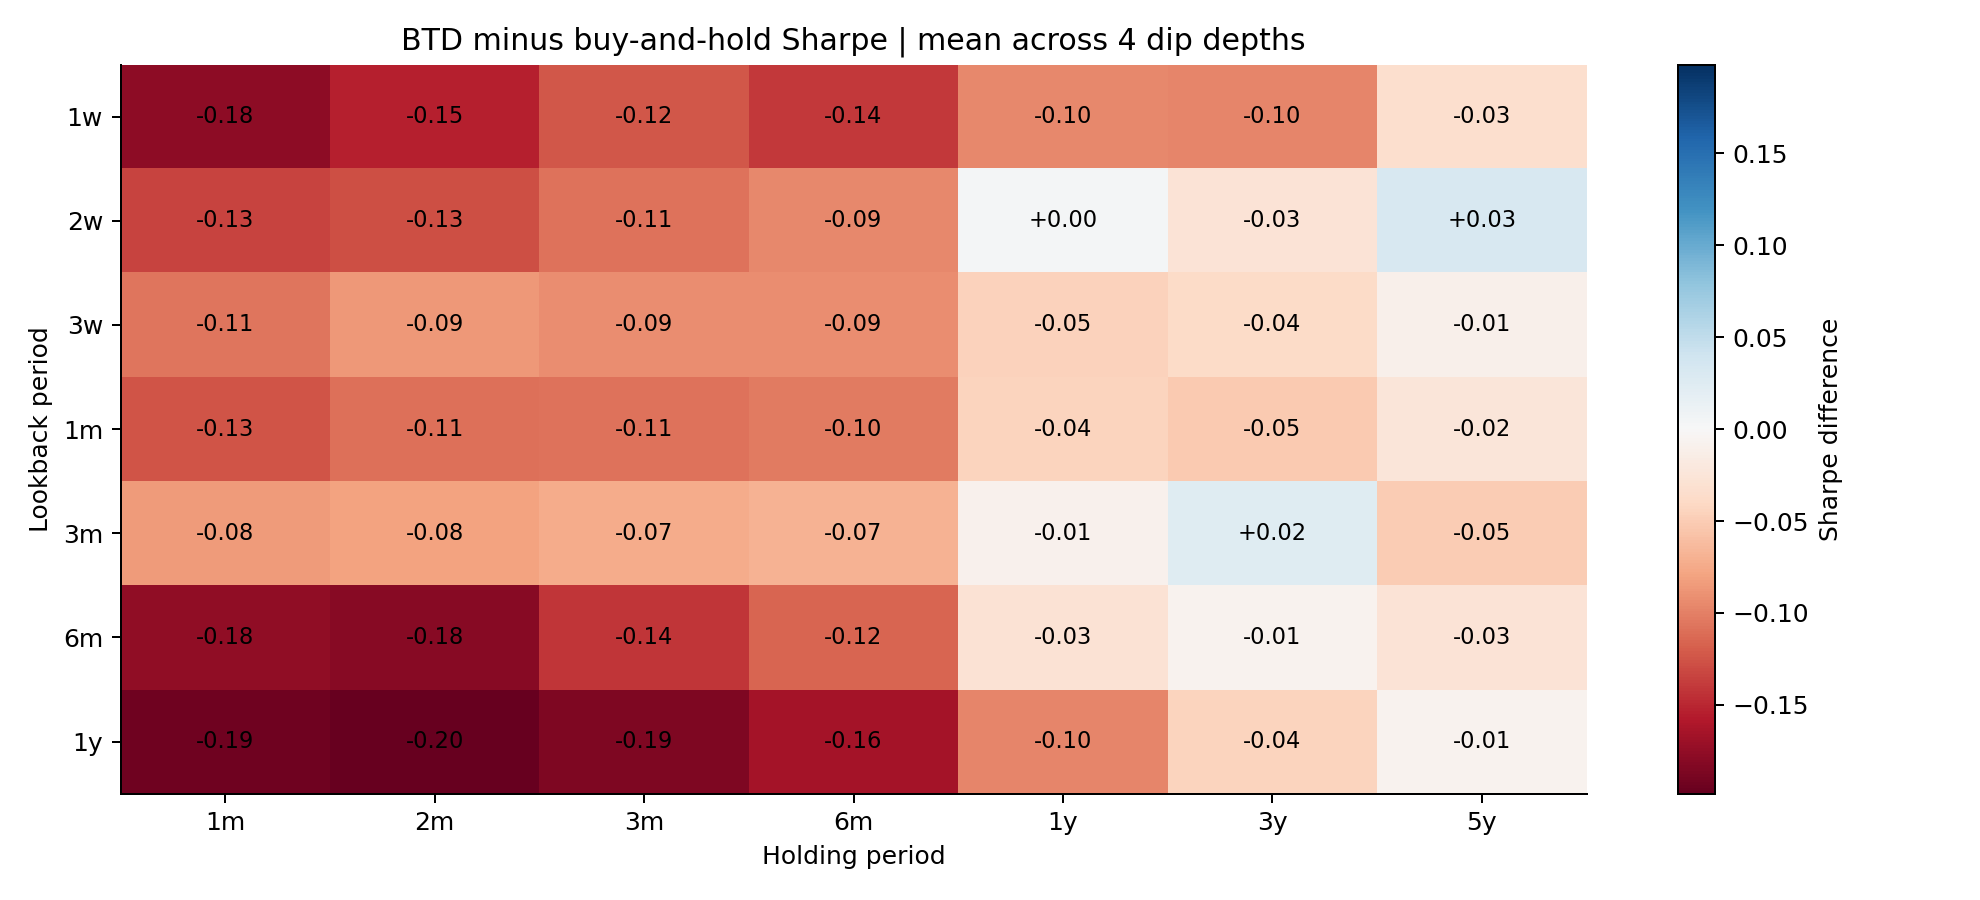

In [4]:
display(Image(filename=str(ROOT / 'outputs/figures/01_sharpe_heatmap.png')))

## 3. 核对一条规则的交易时间

`L21_D10_H63`表示回看21个交易日、下跌达到10%、持有63个股票日收益区间。表中区分信号日、下一收盘成交日和首个股票收益日。相邻持有周期可能在同一次收盘衔接。

In [5]:
trades = pd.read_csv(ROOT / 'outputs/example_trades.csv')
display(trades.head(8))
first = trades.iloc[0]
window = market.loc[first.signal_date:first.first_stock_return_date, ['close','market_return','rf']].copy()
window['held_for_daily_return'] = positions['L21_D10_H63'].reindex(window.index)
display(window)

,strategy,signal_date,buy_close_date,first_stock_return_date,last_stock_return_date,sell_close_date,holding_return_days,gross_stock_trade_return,status
0,L21_D10_H63,1966-08-29,1966-08-30,1966-08-31,1966-11-30,1966-11-30,63,0.060506,closed
1,L21_D10_H63,1970-04-28,1970-04-29,1970-04-30,1970-07-28,1970-07-28,63,-0.049383,closed
2,L21_D10_H63,1973-11-26,1973-11-27,1973-11-28,1974-02-27,1974-02-27,63,0.007315,closed
3,L21_D10_H63,1974-07-08,1974-07-09,1974-07-10,1974-10-07,1974-10-07,63,-0.202872,closed
4,L21_D10_H63,1974-10-04,1974-10-07,1974-10-08,1975-01-07,1975-01-07,63,0.093457,closed
5,L21_D10_H63,1975-08-13,1975-08-14,1975-08-15,1975-11-12,1975-11-12,63,0.065304,closed
6,L21_D10_H63,1978-11-07,1978-11-08,1978-11-09,1979-02-08,1979-02-08,63,0.033880,closed
7,L21_D10_H63,1980-03-13,1980-03-14,1980-03-17,1980-06-13,1980-06-13,63,0.098454,closed


,close,market_return,rf,held_for_daily_return
date,,,,
1966-08-29,74.529999,-0.024604,0.0002,0
1966-08-30,75.860001,0.017845,0.0002,0
1966-08-31,77.099998,0.016346,0.0002,1


## 4. 从仓位重建日收益

股票仓位为0/1，剩余资金进入现金：`策略收益=RF+仓位×市场超额收益`。下面直接用保存的仓位独立复核一条规则的日收益。

In [6]:
sid = 'L21_D10_H63'
base = market.loc[positions.index]
rebuilt = base.rf + positions[sid] * (base.market_return - base.rf)
max_error = np.abs(rebuilt.to_numpy() - daily[sid].to_numpy()).max()
print('CSV重建最大绝对误差：', max_error)
assert max_error < 1e-10
display(pd.concat([positions[sid].rename('weight'), rebuilt.rename('rebuilt_return'), daily[sid].rename('saved_return')], axis=1).loc['2008-09-01':'2008-09-15'])

CSV重建最大绝对误差： 1.734723475976807e-18


,weight,rebuilt_return,saved_return
date,,,
2008-09-02,1,-0.004093,-0.004093
2008-09-03,1,-0.002035,-0.002035
2008-09-04,1,-0.029922,-0.029922
2008-09-05,1,0.004431,0.004431
2008-09-08,1,0.020510,0.020510
2008-09-09,1,-0.034138,-0.034138
2008-09-10,1,0.006149,0.006149
2008-09-11,1,0.013806,0.013806
2008-09-12,1,0.002122,0.002122


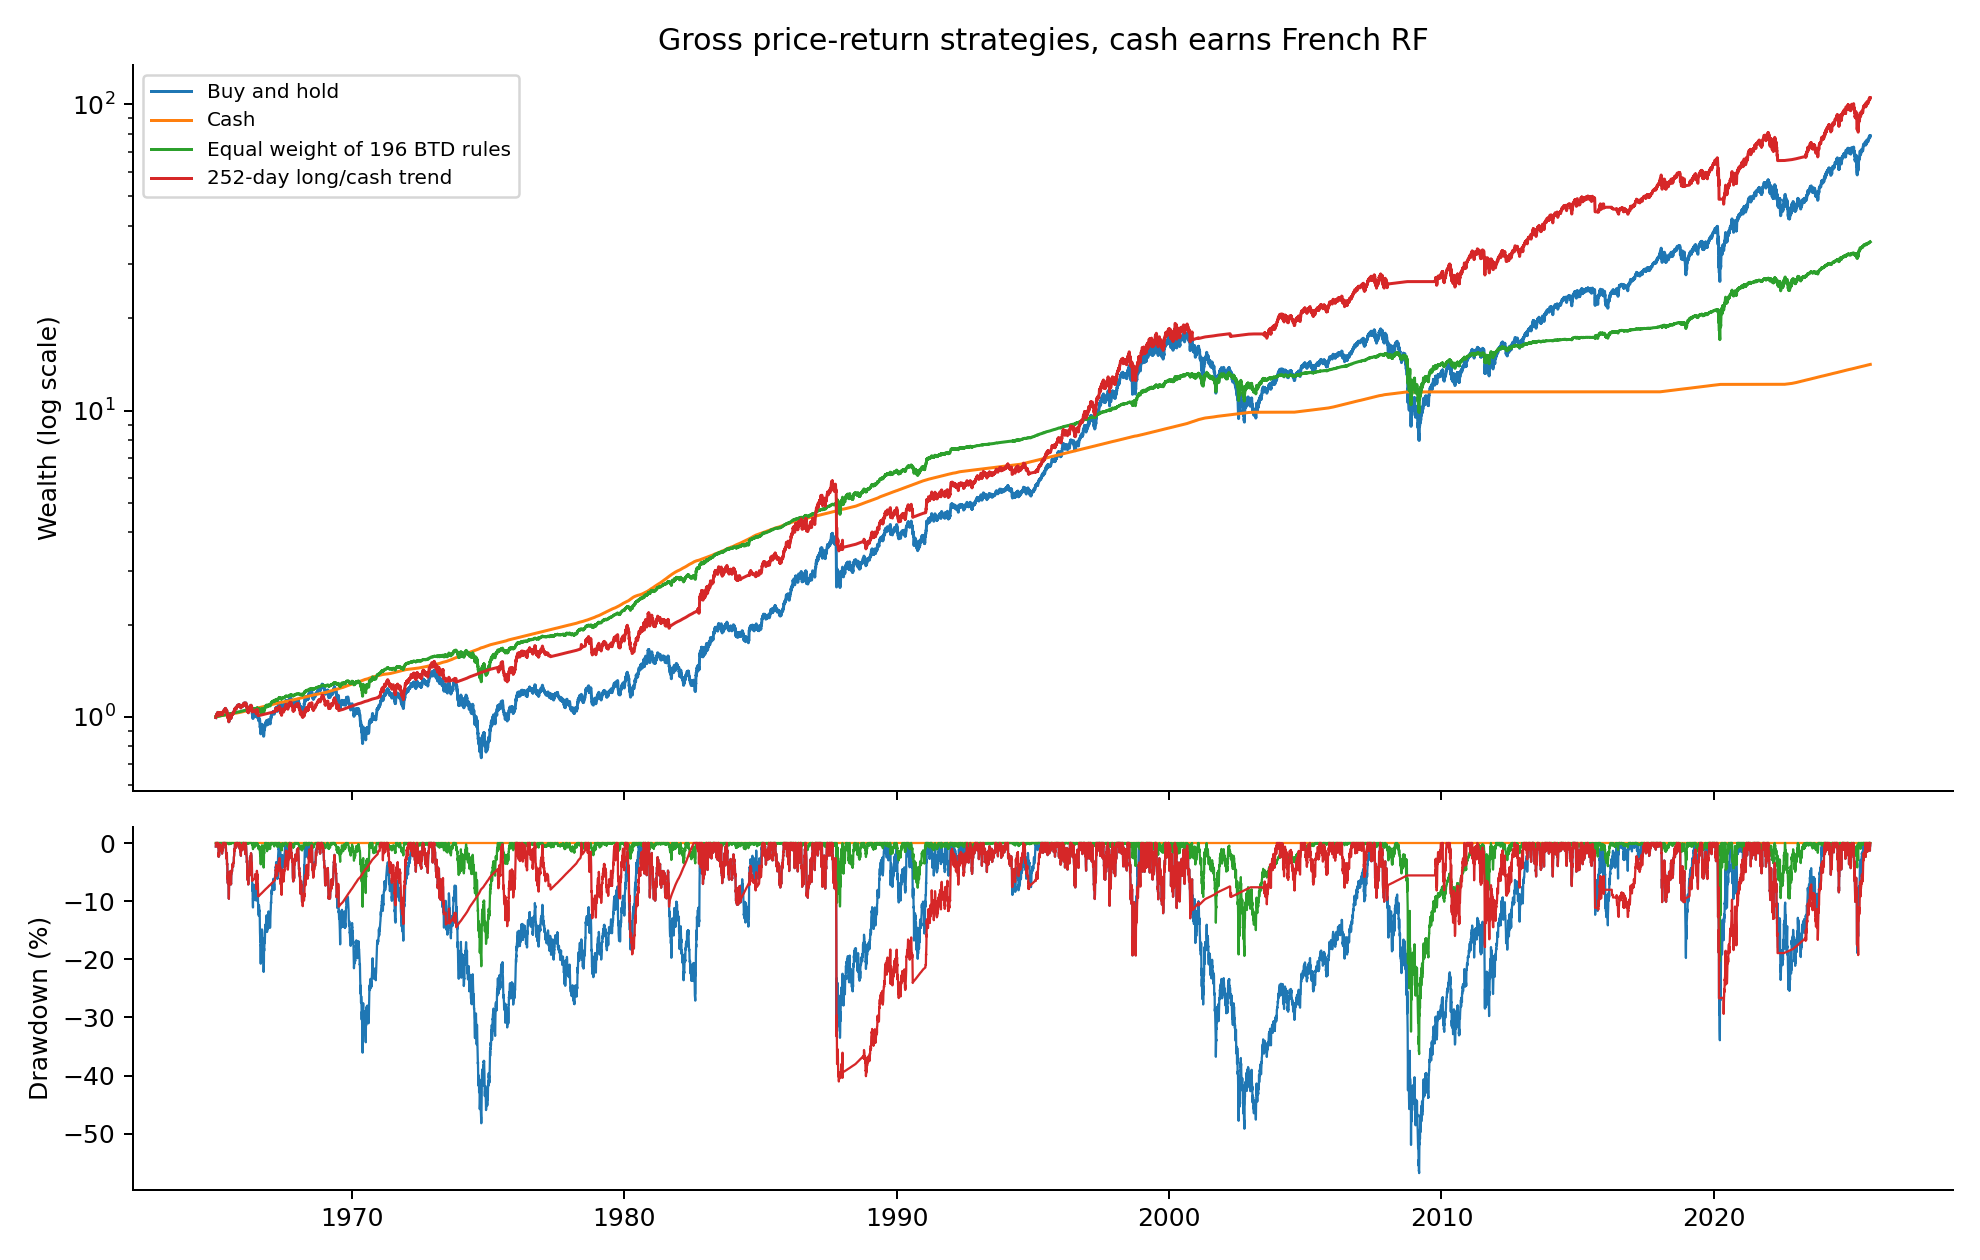

In [7]:
display(Image(filename=str(ROOT / 'outputs/figures/03_nav_drawdown.png')))

## 5. 控制市场暴露之后看alpha

`alpha_ann`是市场超额收益回归截距乘252。主推断使用HAC(21)，`p_holm`进一步对196组假设做Holm校正。

,alpha_ann,beta,t_iid,t_hac,p_hac,p_holm
count,196.000000,196.000000,196.000000,196.000000,196.000000,196.0
mean,0.000860,0.418632,0.084765,0.103757,0.570034,1.0
std,0.007322,0.237547,0.734549,0.773280,0.255826,0.0
min,-0.020098,0.014415,-1.873945,-1.950451,0.019524,1.0
25%,-0.003319,0.229042,-0.375843,-0.420042,0.378248,1.0
50%,0.000846,0.383496,0.110600,0.132178,0.582023,1.0
75%,0.005149,0.580407,0.564073,0.638301,0.785218,1.0
max,0.024243,0.953898,2.285611,2.335375,0.997089,1.0


HAC p<0.05： 1
Holm p<0.05： 0


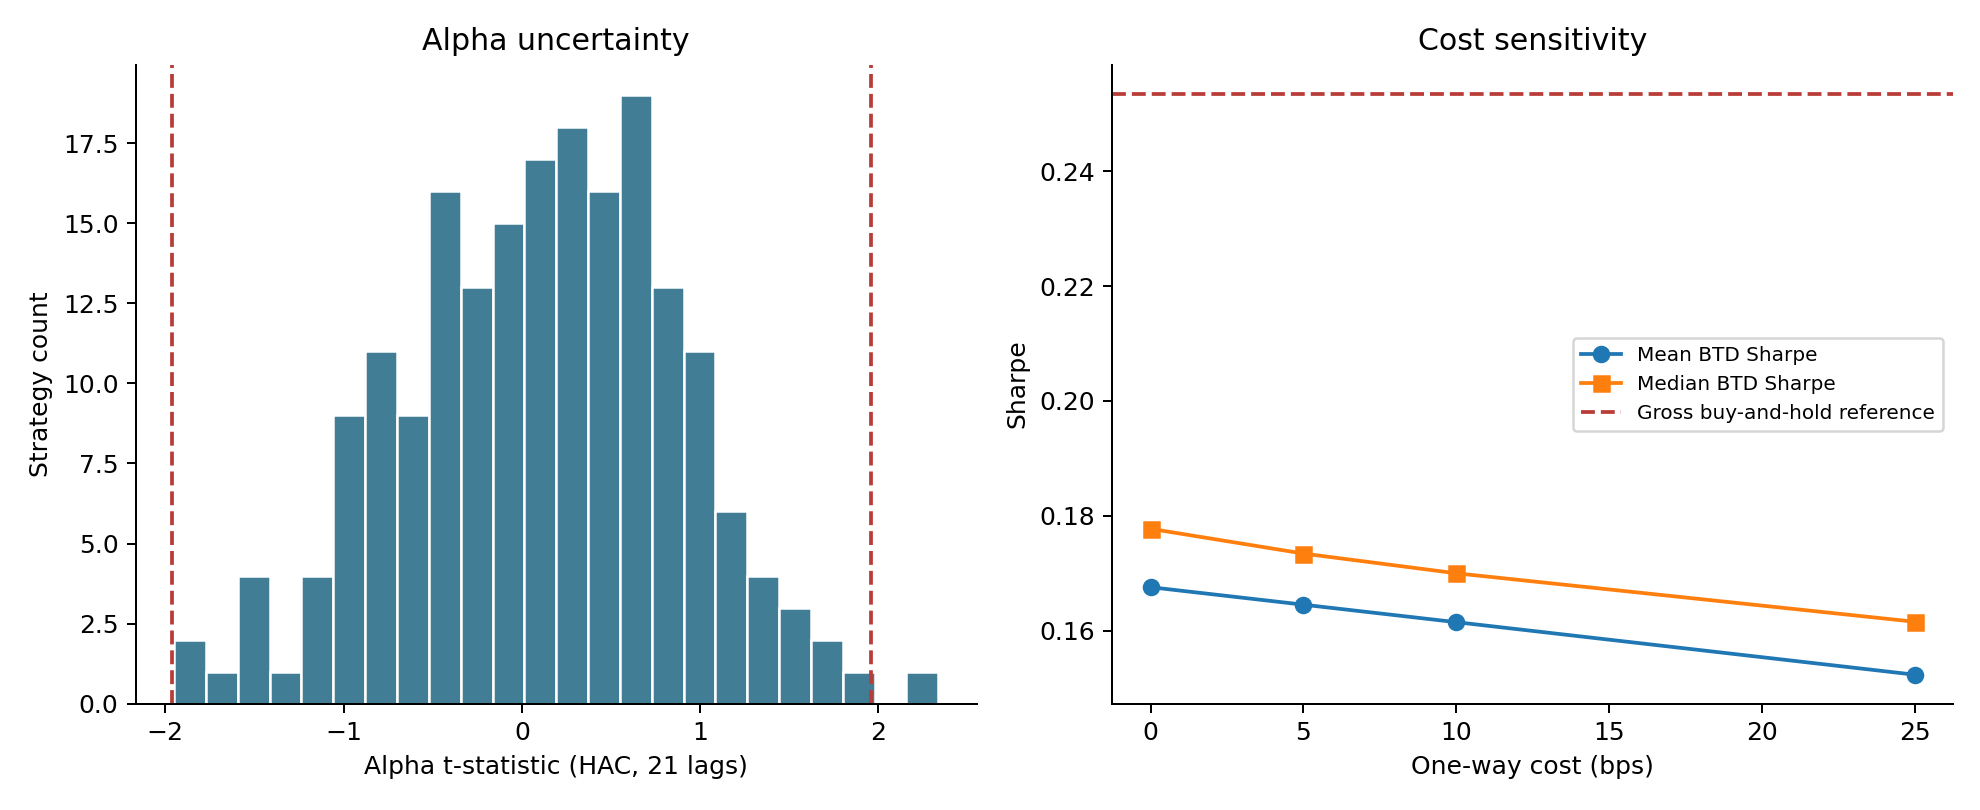

In [8]:
display(grid[['alpha_ann','beta','t_iid','t_hac','p_hac','p_holm']].describe())
print('HAC p<0.05：', int((grid.p_hac < .05).sum()))
print('Holm p<0.05：', int((grid.p_holm < .05).sum()))
display(Image(filename=str(ROOT / 'outputs/figures/04_alpha_cost.png')))

## 6. 实现与阶段敏感性

下面比较延迟一行/两行、忽略重复信号/持仓展期。分阶段观察沿用之前的仓位。发布后窗口为2025-12-02至2026-09-30。

In [9]:
sensitivity = pd.read_csv(ROOT / 'outputs/implementation_sensitivity.csv')
display(sensitivity.groupby(['mode','lag']).sharpe_gap.agg(['mean','median']))
periods = pd.read_csv(ROOT / 'outputs/period_results.csv')
display(periods.groupby('period')[['days','sharpe','benchmark_sharpe','exposure']].mean())

mean    median
mode   lag                    
extend 2   -0.069161 -0.051460
ignore 1   -0.075541 -0.071499
       2   -0.085998 -0.075824

,days,sharpe,benchmark_sharpe,exposure
period,,,,
1965-1989,6285.0,0.107364,-0.001747,0.255878
1990-2009,5043.0,0.069419,0.202083,0.250911
2010-2025Q3,3960.0,0.414677,0.666937,0.275406
after_publication,208.0,1.167534,0.889460,0.173813


## 7. 给自己留三个研究问题

1. 原文与本次平均夏普差的差距，哪些可以通过执行假设解释？
2. 长持有期规则的平均仓位与alpha有怎样的关系？
3. 如果取得含分红ETF与开盘数据，应怎样重新定义可交易回测？

可以从已保存的CSV展开分析，再修改一个清晰设定重跑。完整解读见`outputs/复现结果.md`。